# hiNiche on single-cell spatial data (multi-slice)

> **Environment:** run this notebook in the main **`hiNiche`** environment (`environment.yml`).

This notebook applies hiNiche (`hiNiche_img`, cell → niche) to single-cell resolution spatial data, using the mouse spleen CODEX dataset (three BALBc slices) as an example.

All slices are stored in **one AnnData**; `adata.obs[SAMPLE_KEY]` identifies the slice of each cell. Graphs and niches are built **within each slice**, all slices are **trained jointly**, and the resulting cell / niche embeddings are written back to the same AnnData.

## 1. Imports

In [9]:
import config
import utils
import model
from train import run_train_img

import anndata as ad
import scanpy as sc
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import os
import glob
import warnings
import json
from tqdm import tqdm

from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
from sklearn.cluster import KMeans

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Configuration

Data paths, the slice column (`SAMPLE_KEY`), the ground-truth columns (`LABEL_KEY`, `CELLTYPE_KEY`), the patch root directory (`PATCH_ROOT`) and model / training hyperparameters.

In [ ]:
SAMPLE = "Mouse_spleen_CODEX_multi_slices"

# Data paths: a single AnnData containing all slices
h5_path    = f"DATA/{SAMPLE}/BALBc.h5ad"
SAMPLE_KEY   = "sample"        # adata.obs column identifying the slice of each cell
LABEL_KEY    = "Compartment"   # ground-truth spleen compartment (used for evaluation)
CELLTYPE_KEY = "CellType"      # cell-type annotation (used for visualization)

# Patch root directory: each slice is cached in its own sub-directory PATCH_ROOT/<slice name>
PATCH_ROOT = f"DATA/{SAMPLE}/mini_batch_cache"

# Model save path (if the file exists, the model is loaded and training is skipped)
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint.pt"

# Model / training hyperparameters
single_patch  = True    # each slice is used as a single patch
graph_knn   = 12
niche_knn   = 20
hidden_dim  = 32
lr          = 0.005
num_epochs  = 100
edge_drop   = 0.5
member_drop = 0.5
neg_samples = 5
tau         = 1
seed        = 42
n_clusters  = 4
device      = "cuda:0"

## 3. Load data

Read the AnnData containing all slices. The slices (`SAMPLES`) are taken from `adata.obs[SAMPLE_KEY]`, and each slice gets its own patch directory (`PATCH_LOC`).

In [11]:
adata = sc.read(h5_path)
adata.var_names_make_unique()

# Slices read from adata.obs[SAMPLE_KEY] (in order of appearance); training slice index i <-> SAMPLES[i]
SAMPLES = list(pd.unique(adata.obs[SAMPLE_KEY]))

# Patch save paths: one directory per slice, aligned with SAMPLES
PATCH_LOC = [os.path.join(PATCH_ROOT, str(s)) for s in SAMPLES]

print(adata.obs[SAMPLE_KEY].value_counts().loc[SAMPLES])
print(PATCH_LOC)

sample
BALBc-1    82251
BALBc-2    81346
BALBc-3    80636
Name: count, dtype: int64
['DATA/Mouse_spleen_CODEX_multi_slices/mini_batch_cache/BALBc-1', 'DATA/Mouse_spleen_CODEX_multi_slices/mini_batch_cache/BALBc-2', 'DATA/Mouse_spleen_CODEX_multi_slices/mini_batch_cache/BALBc-3']


## 4. Build graphs, niches and mini-batches per slice

In [12]:
# ===== Per-slice preprocessing + block construction =====
# Graphs and niches are built within each slice (no cross-slice edges);
# slice SAMPLES[i] is cached in PATCH_LOC[i].
sample_number_list = []

for s, save_dir in zip(SAMPLES, PATCH_LOC):
    adata_s = adata[adata.obs[SAMPLE_KEY] == s].copy()
    adata_s.layers["counts"] = adata_s.X.copy()

    X_backup = adata_s.X.copy()
    sc.pp.scale(adata_s)
    sc.tl.pca(adata_s, n_comps=25)
    adata_s.X = X_backup

    adata_s.obsm["X_input"] = adata_s.X
    adata_s.obsm["X_mle"] = adata_s.layers["counts"]
    spatial_coords_px = adata_s.obsm["spatial"]

    # Each niche = a center cell and its niche_knn nearest cells (including itself)
    S_c2n_all, _, _ = utils.build_cell_niche_mapping_knn(spatial_coords_px, k_niche = niche_knn)

    cell_edges = utils.build_spot_knn_graph(adata_s.obsm["X_pca"], graph_knn)    # cell graph: expression (PCA) KNN
    niche_edges = utils.build_spot_knn_graph(spatial_coords_px, graph_knn)       # niche graph: spatial KNN
    batch_mask, block_ids = utils.make_cell_block_masks(spatial_coords_px, S_c2n = S_c2n_all, single_patch = single_patch)

    # Remove old blocks, otherwise the loader would also read leftovers from a previous run
    for f in glob.glob(os.path.join(save_dir, "block_*.pt")):
        os.remove(f)
    utils.build_cell_subgraph_data(adata_s, ref_matrix = None,
                               cell_edges = cell_edges,
                               niche_edges = niche_edges,
                               S_c2n_all = S_c2n_all,
                               batch_mask = batch_mask,
                               block_ids = block_ids,
                               save_dir = save_dir)

    sample_number_list.append({"cell": S_c2n_all.shape[0], "niche": S_c2n_all.shape[1]})
    del adata_s

[Log] Active niches: 82251, Cells per niche (k): 20
[Log] 1626368 edges generated from 82251 nodes (k=12)
[Log] 1077382 edges generated from 82251 nodes (k=12)


[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:01<00:00,  1.67s/it]


[Log] saved 1 cell blocks → DATA/Mouse_spleen_CODEX_multi_slices/mini_batch_cache/BALBc-1
[Log] Active niches: 81346, Cells per niche (k): 20
[Log] 1597830 edges generated from 81346 nodes (k=12)
[Log] 1066190 edges generated from 81346 nodes (k=12)


[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:01<00:00,  1.70s/it]


[Log] saved 1 cell blocks → DATA/Mouse_spleen_CODEX_multi_slices/mini_batch_cache/BALBc-2
[Log] Active niches: 80636, Cells per niche (k): 20
[Log] 1576092 edges generated from 80636 nodes (k=12)
[Log] 1058806 edges generated from 80636 nodes (k=12)


[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:01<00:00,  1.69s/it]

[Log] saved 1 cell blocks → DATA/Mouse_spleen_CODEX_multi_slices/mini_batch_cache/BALBc-3


## 5. Joint multi-slice training

All slices are trained together. If `MODEL_SAVE_DIR` already exists, the model is loaded and training is skipped. Embeddings are written to `adata.obsm["X_cell_emb"]` and `adata.obsm["X_niche_emb"]`.

In [13]:
# ===== Joint multi-slice training: sample_number_list and PATCH_LOC are lists aligned with SAMPLES =====
emb_all, slice_ids = run_train_img(sample_number_list,
                                   PATCH_LOC = PATCH_LOC,
                                   MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                                   ref_matrix = None,
                                   lr = lr,
                                   in_dim = adata.n_vars,
                                   hidden_dim = hidden_dim,
                                   num_epochs = num_epochs,
                                   edge_drop = edge_drop,
                                   member_drop = member_drop,
                                   neg_samples = neg_samples,
                                   tau = tau,
                                   seed = seed,
                                   device = device)

# Write the embeddings back to the single adata (rows of slice i -> cells of SAMPLES[i], same order).
# With KNN niches every cell is a niche center, so niche embeddings are aligned with cells as well.
adata.obsm["X_cell_emb"]  = np.zeros((adata.n_obs, hidden_dim), dtype=np.float32)
adata.obsm["X_niche_emb"] = np.zeros((adata.n_obs, hidden_dim), dtype=np.float32)
for i, s in enumerate(SAMPLES):
    mask = (adata.obs[SAMPLE_KEY] == s).values
    adata.obsm["X_cell_emb"][mask]  = emb_all["cell"][slice_ids["cell"] == i].detach().cpu().numpy()
    adata.obsm["X_niche_emb"][mask] = emb_all["niche"][slice_ids["niche"] == i].detach().cpu().numpy()

Epoch 100: 100%|██████████| 3/3 [00:00<00:00,  8.53it/s, cl=2.7646]


Training finished!
Model saved to DATA/Mouse_spleen_CODEX_multi_slices/checkpoint_42.pt


generating embeddings (slice 2)...: 100%|██████████| 1/1 [00:00<00:00,  7.70it/s]


## 6. Clustering and visualization

KMeans on the cell and niche embeddings within each slice, plotted next to the ground-truth cell types (`CELLTYPE_KEY`) and compartments (`LABEL_KEY`). Labels are stored in `adata.obs["kmeans_cell"]` / `adata.obs["kmeans_niche"]` (comparable only within a slice).

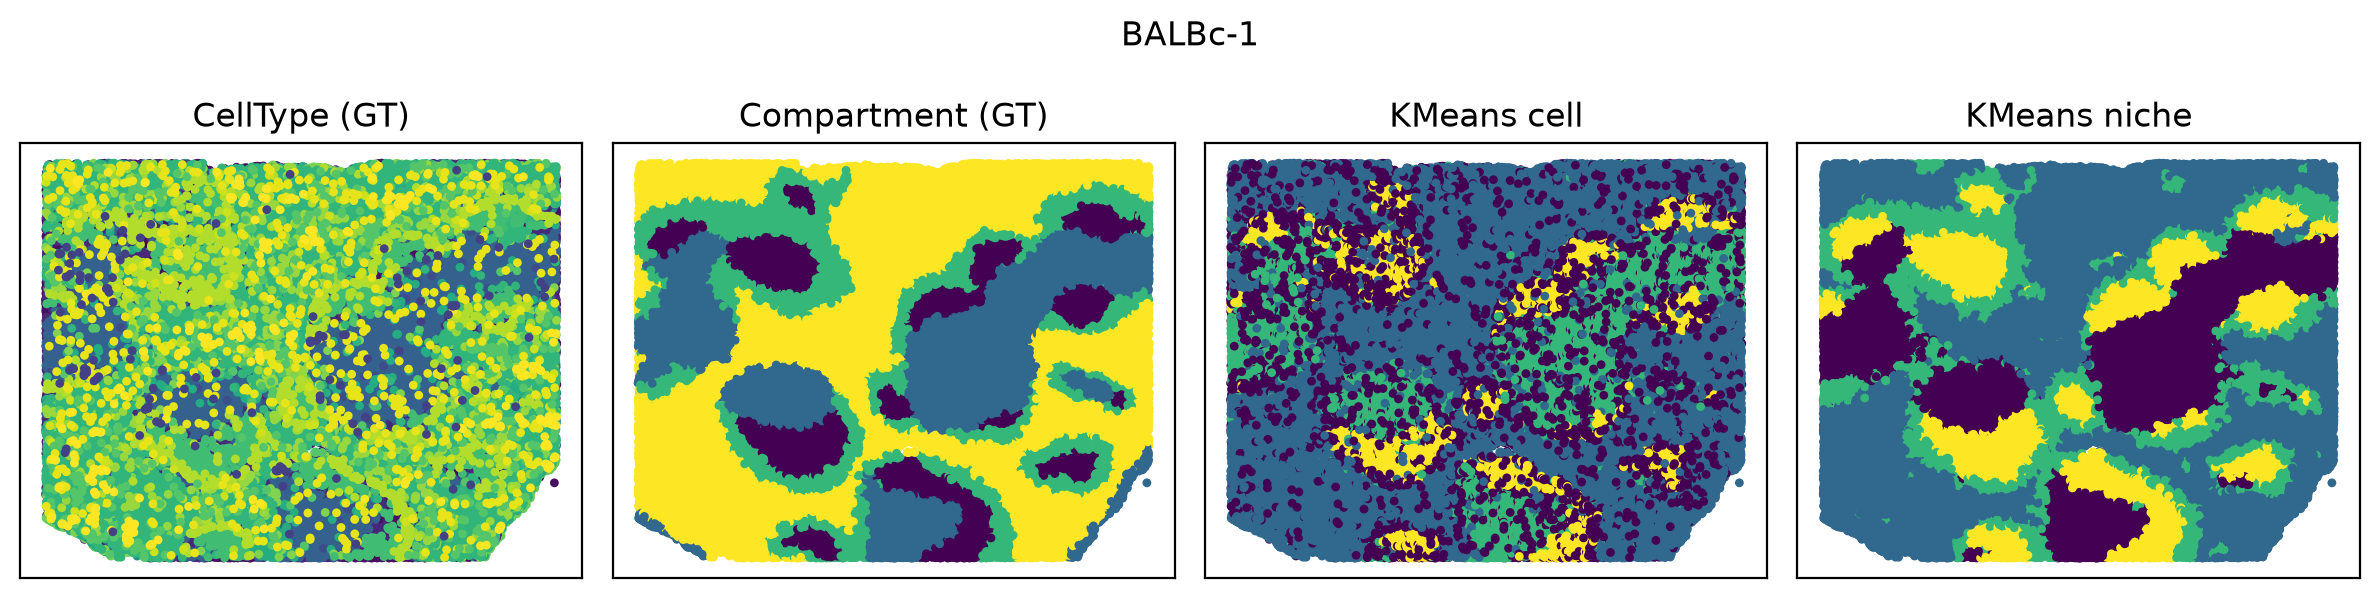

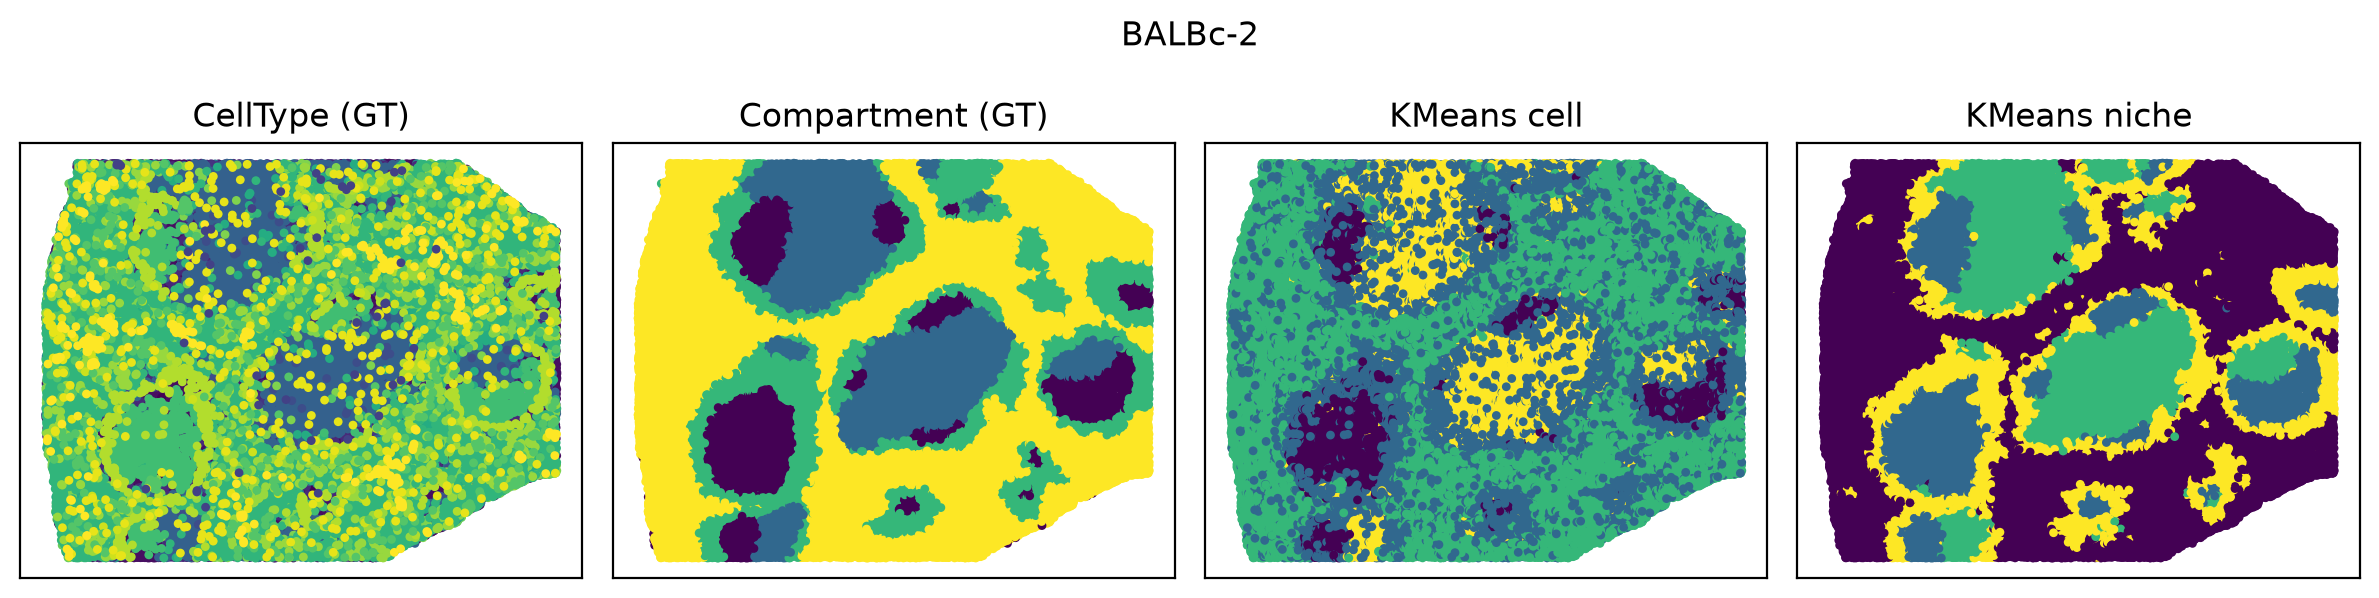

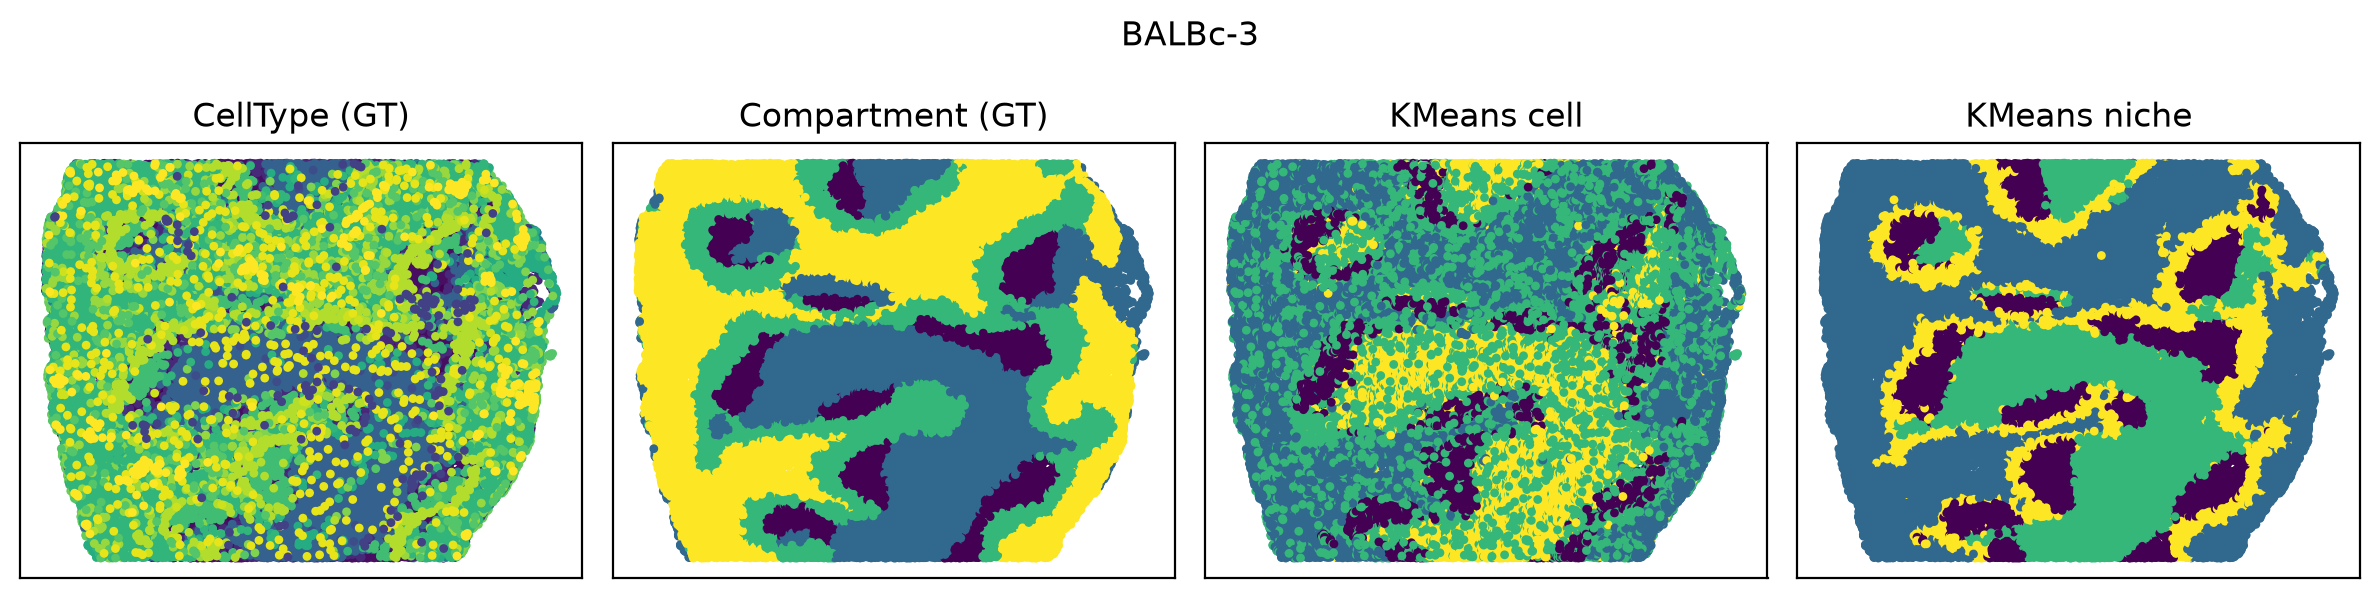

In [14]:
results_cell = {}
results_niche = {}
niche_save = {}

kmeans_cell  = np.empty(adata.n_obs, dtype=object)
kmeans_niche = np.empty(adata.n_obs, dtype=object)

for i, s in enumerate(SAMPLES):
    mask = (adata.obs[SAMPLE_KEY] == s).values
    sub = adata[mask]
    spatial = sub.obsm["spatial"]
    x, y = spatial[:, 0], spatial[:, 1]

    X_cell  = np.asarray(sub.obsm["X_cell_emb"])
    X_niche = np.asarray(sub.obsm["X_niche_emb"])

    # KMeans is run separately within each slice
    labels_cell  = KMeans(n_clusters=n_clusters, random_state=42, n_init=20).fit_predict(X_cell)
    labels_niche = KMeans(n_clusters=n_clusters, random_state=42, n_init=20).fit_predict(X_niche)

    kmeans_cell[mask]  = labels_cell.astype(str)
    kmeans_niche[mask] = labels_niche.astype(str)

    # Ground-truth labels
    point_size = 10
    celltype = sub.obs[CELLTYPE_KEY].astype("category")
    comp = sub.obs[LABEL_KEY].astype("category")

    fig, axes = plt.subplots(1, 4, figsize=(12, 3), dpi=200)
    panels = [(celltype.cat.codes, f"{CELLTYPE_KEY} (GT)"),
              (comp.cat.codes,     f"{LABEL_KEY} (GT)"),
              (labels_cell,        "KMeans cell"),
              (labels_niche,       "KMeans niche")]
    for ax, (c, title) in zip(axes, panels):
        ax.scatter(x, y, c=c, s=point_size, linewidths=0)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(title)
    fig.suptitle(s)
    plt.tight_layout()
    plt.show()

    true_labels = sub.obs[LABEL_KEY]
    nmi_cell  = normalized_mutual_info_score(true_labels, labels_cell)
    ari_cell  = adjusted_rand_score(true_labels, labels_cell)
    nmi_niche = normalized_mutual_info_score(true_labels, labels_niche)
    ari_niche = adjusted_rand_score(true_labels, labels_niche)

    results_cell[s]  = [nmi_cell, ari_cell]
    results_niche[s] = [nmi_niche, ari_niche]
    niche_save[s]    = labels_niche.astype(str)

# Per-slice cluster labels stored in the single adata (labels are only comparable within a slice)
adata.obs["kmeans_cell"]  = pd.Categorical(kmeans_cell)
adata.obs["kmeans_niche"] = pd.Categorical(kmeans_niche)

## 7. Evaluation (NMI / ARI)

Agreement of the cell and niche clusters with the ground-truth compartments (`LABEL_KEY`), per slice and averaged.

In [15]:
slice_list = SAMPLES

# Per-slice results
for s in slice_list:
    nmi_c, ari_c = results_cell[s]
    nmi_n, ari_n = results_niche[s]
    print(s)
    print(f"Cell:  NMI: {nmi_c:.4f}, ARI: {ari_c:.4f}")
    print(f"Niche: NMI: {nmi_n:.4f}, ARI: {ari_n:.4f}")

cell_arr  = np.array([results_cell[s]  for s in slice_list], dtype=float)   # [S, 2]
niche_arr = np.array([results_niche[s] for s in slice_list], dtype=float)   # [S, 2]

cell_mean_nmi,  cell_mean_ari  = cell_arr.mean(axis=0)
niche_mean_nmi, niche_mean_ari = niche_arr.mean(axis=0)

print(f"Cell (mean):  NMI: {cell_mean_nmi:.4f}, ARI: {cell_mean_ari:.4f}")
print(f"Niche(mean): NMI: {niche_mean_nmi:.4f}, ARI: {niche_mean_ari:.4f}")

BALBc-1
Cell:  NMI: 0.3064, ARI: 0.2585
Niche: NMI: 0.6233, ARI: 0.6719
BALBc-2
Cell:  NMI: 0.3344, ARI: 0.2139
Niche: NMI: 0.6367, ARI: 0.6765
BALBc-3
Cell:  NMI: 0.3030, ARI: 0.2098
Niche: NMI: 0.6163, ARI: 0.6535
Cell (mean):  NMI: 0.3146, ARI: 0.2274
Niche(mean): NMI: 0.6254, ARI: 0.6673


## 8. Summary plot

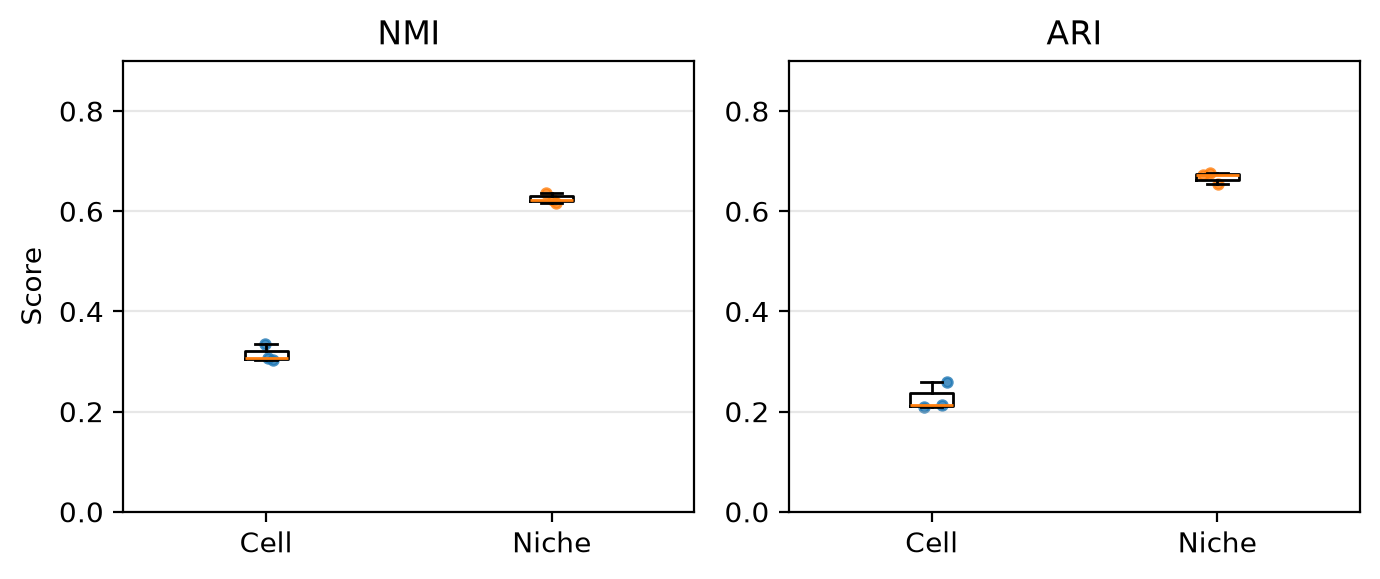

In [16]:
cell_nmi, cell_ari   = cell_arr[:, 0], cell_arr[:, 1]
niche_nmi, niche_ari = niche_arr[:, 0], niche_arr[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(7, 3), dpi=200)
rng = np.random.default_rng(0)

for ax, (c_vals, n_vals, title) in zip(axes, [(cell_nmi, niche_nmi, "NMI"),
                                             (cell_ari, niche_ari, "ARI")]):
    ax.boxplot([c_vals, n_vals], tick_labels=["Cell", "Niche"], showfliers=False)
    ax.scatter(1 + rng.normal(0, 0.04, size=len(c_vals)), c_vals, s=12, alpha=0.8)
    ax.scatter(2 + rng.normal(0, 0.04, size=len(n_vals)), n_vals, s=12, alpha=0.8)
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_ylim(0, 0.9)
    ax.set_yticks(np.arange(0, 0.9 + 1e-9, 0.2))
axes[0].set_ylabel("Score")

plt.tight_layout()
plt.show()